# 04 — First-move results, chance baseline and preliminary models

Run after notebook 03 completes. This notebook makes no inference calls. The primary outcome is assisted selection of the exact official first move, not complete puzzle solving. Both prior full-sequence experiments remain unchanged in the archive.

Uniform random legal selection succeeds with probability **1 / legal move count** on each puzzle. We report the exact expected number correct and an exact Poisson-binomial upper-tail probability for each model. Holm correction accounts for the three model comparisons. These are exploratory comparisons on a deliberately balanced diagnostic sample, not population estimates or confirmatory evidence.

Predictive models use the fixed 36/12 puzzle-level train/test partition recorded before collection. With sparse outcomes, models are demonstrations of the analysis pipeline; coefficient signs and small held-out metrics should not be treated as stable research findings.

In [1]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'experiments/first_move_v1/config.json').is_file())
EXP=ROOT/'data/experiments/first_move_v1'
OUT=ROOT/'data/analysis/first_move_v1';OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures/first_move_v1';FIG.mkdir(parents=True,exist_ok=True)
sample=pd.read_csv(EXP/'puzzles.csv',dtype={'puzzle_id':str})
attempts=pd.read_csv(EXP/'outcomes.csv',dtype={'puzzle_id':str})
assert not attempts.duplicated(['puzzle_id','llm_name']).any() and len(attempts)==144
audit=json.loads((EXP/'audit_summary.json').read_text());assert audit['status']=='passed'
data=attempts.loc[attempts.status.eq('completed')].merge(sample,on='puzzle_id',validate='many_to_one')
data['success']=data.success.astype(int)
data['rating_100']=data.puzzle_rating/100
data.to_csv(OUT/'modeling_table.csv',index=False)
display(data.groupby('llm_name').agg(n=('success','size'),correct=('success','sum'),accuracy=('success','mean')))


,n,correct,accuracy
llm_name,,,
gemma3:4b,48,1,0.020833
llama3.1:8b,48,2,0.041667
qwen3:8b,48,3,0.062500


## Exact chance comparison

The null is a uniform independent random legal choice on each puzzle. Legal move counts differ, so a single binomial probability is inappropriate. The dynamic-programming calculation below gives the full Poisson-binomial distribution without Monte Carlo error. A small p-value establishes a difference from this particular random policy, not strong chess ability or an association with human rating.

,llm_name,n,correct,accuracy,random_expected_correct,random_expected_accuracy,accuracy_minus_chance,exact_p_above_chance,holm_adjusted_p
0,gemma3:4b,48,1,0.020833,1.983845,0.04133,-0.020497,0.872720,1.000000
1,llama3.1:8b,48,2,0.041667,1.983845,0.04133,0.000337,0.599529,1.000000
2,qwen3:8b,48,3,0.062500,1.983845,0.04133,0.021170,0.318256,0.954769


n  correct  accuracy  \
llm_name    rating_stratum length_group                         
gemma3:4b   high           multi_move    8        1     0.125   
                           one_move      8        0     0.000   
            low            multi_move    8        0     0.000   
                           one_move      8        0     0.000   
            middle         multi_move    8        0     0.000   
                           one_move      8        0     0.000   
llama3.1:8b high           multi_move    8        0     0.000   
                           one_move      8        1     0.125   
            low            multi_move    8        0     0.000   
                           one_move      8        0     0.000   
            middle         multi_move    8        1     0.125   
                           one_move      8        0     0.000   
qwen3:8b    high           multi_move    8        0     0.000   
                           one_move      8        1     0.125   
            low            multi_move    8        0     0.000   
                           one_move      8        1     0.125   
            middle         multi_move    8        0     0.000   
                           one_move      8        1     0.125   

                                         random_expected_accuracy  
llm_name    rating_stratum length_group                            
gemma3:4b   high           multi_move                    0.081613  
                           one_move                      0.032894  
            low            multi_move                    0.042509  
                           one_move                      0.034616  
            middle         multi_move                    0.027257  
                           one_move                      0.029092  
llama3.1:8b high           multi_move                    0.081613  
                           one_move                      0.032894  
            low            multi_move                    0.042509  
                           one_move                      0.034616  
            middle         multi_move                    0.027257  
                           one_move                      0.029092  
qwen3:8b    high           multi_move                    0.081613  
                           one_move                      0.032894  
            low            multi_move                    0.042509  
                           one_move                      0.034616  
            middle         multi_move                    0.027257  
                           one_move                      0.029092

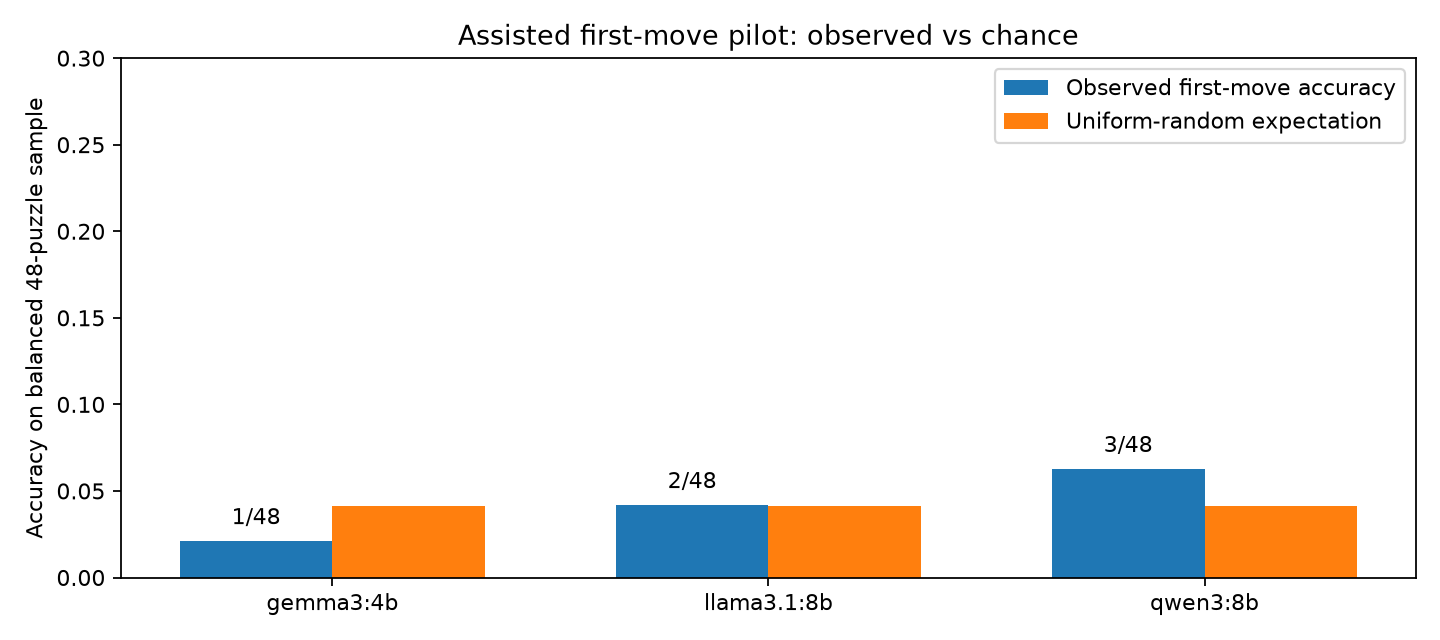

In [2]:
def chance_tail(probabilities,observed):
    pmf=np.array([1.0])
    for p in probabilities:pmf=np.convolve(pmf,[1-p,p])
    return float(min(1.0,pmf[int(observed):].sum()))
assert abs(chance_tail([.5,.5],2)-.25)<1e-12
assert abs(chance_tail([1.,0.],1)-1.)<1e-12
assert abs(chance_tail([.1,.2],0)-1.)<1e-12
rows=[]
for name,group in data.groupby('llm_name'):
    n=len(group);k=int(group.success.sum());expected=float(group.random_success_probability.sum())
    rows.append({'llm_name':name,'n':n,'correct':k,'accuracy':k/n,'random_expected_correct':expected,
        'random_expected_accuracy':expected/n,'accuracy_minus_chance':(k-expected)/n,
        'exact_p_above_chance':chance_tail(group.random_success_probability.to_numpy(),k)})
comparison=pd.DataFrame(rows)
order=np.argsort(comparison.exact_p_above_chance.to_numpy(),kind='stable')
ordered=comparison.exact_p_above_chance.to_numpy()[order]
adjusted=np.minimum(1,np.maximum.accumulate(ordered*(len(ordered)-np.arange(len(ordered)))))
holm=np.empty(len(ordered));holm[order]=adjusted
comparison['holm_adjusted_p']=holm
comparison.to_csv(OUT/'chance_comparison.csv',index=False)
subgroups=data.groupby(['llm_name','rating_stratum','length_group']).agg(
    n=('success','size'),correct=('success','sum'),accuracy=('success','mean'),
    random_expected_accuracy=('random_success_probability','mean'))
subgroups.to_csv(OUT/'subgroup_results.csv')
pd.crosstab(data.llm_name,data.failure_type).to_csv(OUT/'failure_counts.csv')
display(comparison);display(subgroups)
fig,ax=plt.subplots(figsize=(9,4))
x=np.arange(len(comparison));width=.35
ax.bar(x-width/2,comparison.accuracy,width,label='Observed first-move accuracy')
ax.bar(x+width/2,comparison.random_expected_accuracy,width,label='Uniform-random expectation')
ax.set(xticks=x,xticklabels=comparison.llm_name,ylabel='Accuracy on balanced 48-puzzle sample',ylim=(0,max(.3,float(comparison.accuracy.max())+.1)),title='Assisted first-move pilot: observed vs chance')
for i,row in enumerate(comparison.itertuples()):ax.text(i-width/2,row.accuracy+.01,f'{row.correct}/{row.n}',ha='center')
ax.legend();fig.tight_layout();fig.savefig(FIG/'accuracy_vs_chance.png',dpi=160);plt.close(fig)
display(Image(filename=str(FIG/'accuracy_vs_chance.png')))


## Preliminary logistic regression and decision tree

The analysis uses training-only preprocessing, fixed model settings, and no tuning on test outcomes. Both models use human rating, solution length, legal move count, piece count, material balance, and model identity. A majority-class baseline uses the training prevalence.

L2 logistic coefficients are regularized and standardized; they are not unpenalized odds ratios or significance tests. A separate exploratory rating-plus-model GLM with puzzle-clustered standard errors is attempted only when outcomes are less sparse. The single tree demonstrates the pipeline; XGBoost and a larger main study remain later work.

,feature,standardized_L2_coefficient
0,numeric__rating_100,0.112979
1,numeric__total_solver_moves,-0.471215
2,numeric__legal_moves,-0.553750
3,numeric__piece_count,0.361766
4,numeric__material_balance,0.689899
5,model_identity__llm_name_llama3.1:8b,-0.180302
6,model_identity__llm_name_qwen3:8b,0.584929


,model,test_n,test_successes,predicted_successes,accuracy,balanced_accuracy,roc_auc,brier_score
0,majority_baseline,36,1,0,0.972222,0.5,0.500000,0.027349
1,logistic_regression,36,1,0,0.972222,0.5,0.485714,0.029340
2,decision_tree,36,1,0,0.972222,0.5,0.285714,0.034038


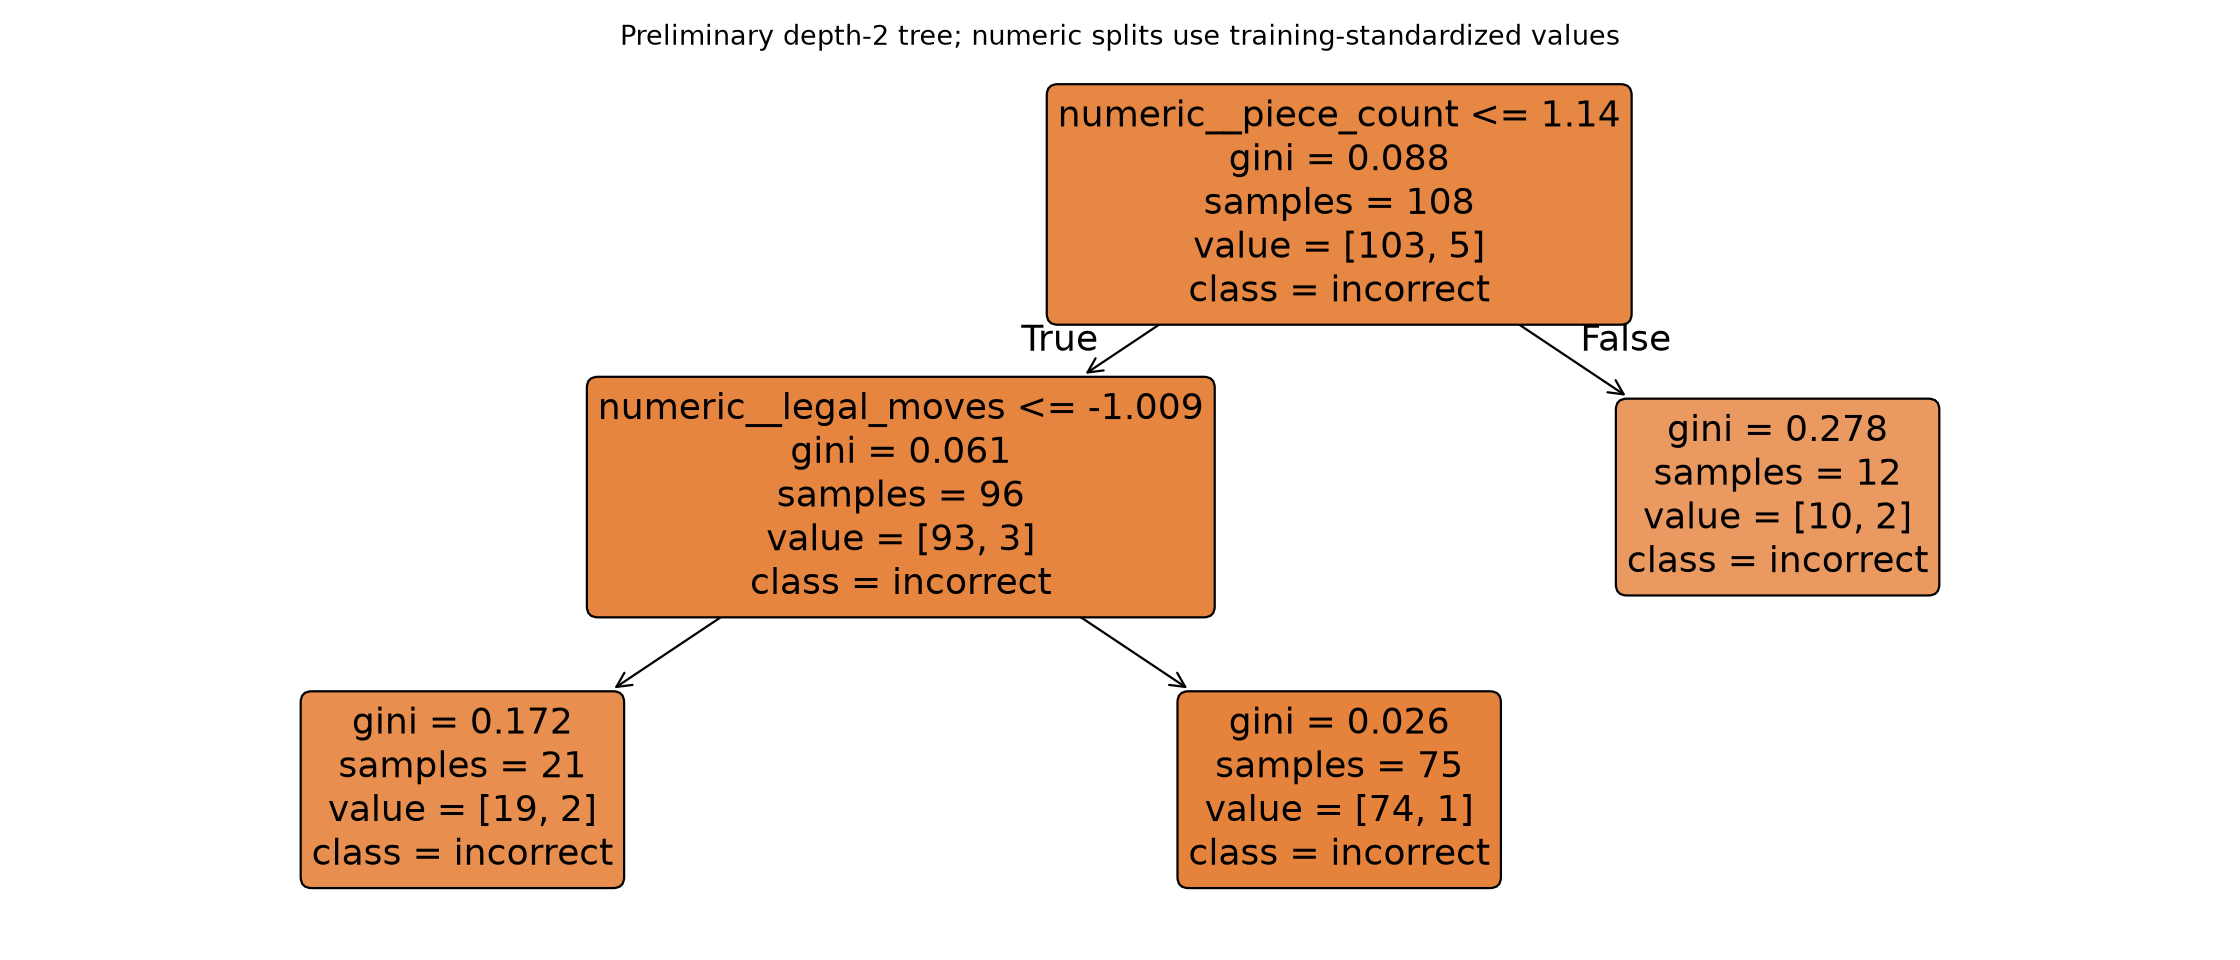

Fitted regularized logistic regression and shallow decision tree. Sparse pilot results are exploratory demonstrations, not stable estimates.


In [3]:
import joblib
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score,balanced_accuracy_score,roc_auc_score,brier_score_loss
train=data.loc[data.partition.eq('train')].copy();test=data.loc[data.partition.eq('test')].copy()
assert not set(train.puzzle_id)&set(test.puzzle_id)
assert sample.partition.value_counts().to_dict()=={'train':36,'test':12}
counts=train.success.value_counts()
summary={'n_puzzles':48,'attempts_recorded':len(attempts),'attempts_scored':len(data),
    'infrastructure_errors':int(attempts.status.ne('completed').sum()),
    'training_class_counts':{str(k):int(v) for k,v in counts.items()},
    'train_puzzles':int(train.puzzle_id.nunique()),'test_puzzles':int(test.puzzle_id.nunique()),
    'any_model_above_random_after_holm':bool(comparison.holm_adjusted_p.le(.05).any()),
    'audit':audit,'outcome':'Assisted exact official first move, not full sequence',
    'inference_status':'Clustered coefficient inference deferred: only six successes in the entire pilot; not enough information for reliable association estimates.'}
metrics=[]
if len(counts)<2 or min(counts)<5 or len(test)==0:
    summary['model_status']='Deferred: fewer than 5 successes or failures in the fixed training set. Split not redrawn.'
else:
    numeric=['rating_100','total_solver_moves','legal_moves','piece_count','material_balance']
    categorical=['llm_name'];columns=numeric+categorical
    estimators={'majority_baseline':DummyClassifier(strategy='prior'),
        'logistic_regression':LogisticRegression(C=1,max_iter=2000,random_state=421),
        'decision_tree':DecisionTreeClassifier(max_depth=2,min_samples_leaf=10,random_state=421)}
    predictions=test[['puzzle_id','llm_name','success']].copy()
    for name,estimator in estimators.items():
        prep=ColumnTransformer([('numeric',StandardScaler(),numeric),
            ('model_identity',OneHotEncoder(drop='first',handle_unknown='ignore'),categorical)])
        pipeline=Pipeline([('preprocess',prep),('model',estimator)])
        pipeline.fit(train[columns],train.success)
        probabilities=pipeline.predict_proba(test[columns])[:,1]
        predicted=pipeline.predict(test[columns])
        metrics.append({'model':name,'test_n':len(test),'test_successes':int(test.success.sum()),
            'predicted_successes':int(predicted.sum()),'accuracy':accuracy_score(test.success,predicted),'balanced_accuracy':balanced_accuracy_score(test.success,predicted),
            'roc_auc':float(roc_auc_score(test.success,probabilities)) if test.success.nunique()==2 else None,
            'brier_score':brier_score_loss(test.success,probabilities)})
        predictions[name+'_probability']=probabilities
        joblib.dump(pipeline,OUT/(name+'.joblib'))
        names=pipeline.named_steps['preprocess'].get_feature_names_out()
        if name=='logistic_regression':
            coefficients=pd.DataFrame({'feature':names,'standardized_L2_coefficient':estimator.coef_[0]})
            coefficients.to_csv(OUT/'logistic_coefficients.csv',index=False);display(coefficients)
        if name=='decision_tree':
            fig,ax=plt.subplots(figsize=(14,6))
            plot_tree(estimator,feature_names=names,class_names=['incorrect','correct'],rounded=True,filled=True,ax=ax)
            ax.set_title('Preliminary depth-2 tree; numeric splits use training-standardized values')
            fig.tight_layout();fig.savefig(FIG/'decision_tree.png',dpi=160);plt.close(fig)
    predictions.to_csv(OUT/'test_predictions.csv',index=False)
    pd.DataFrame(metrics).to_csv(OUT/'model_metrics.csv',index=False)
    summary['model_status']='Fitted regularized logistic regression and shallow decision tree. Sparse pilot results are exploratory demonstrations, not stable estimates.'
    summary['metrics']=metrics
    display(pd.DataFrame(metrics));display(Image(filename=str(FIG/'decision_tree.png')))
    if min(data.success.value_counts())>=20 and data.groupby('llm_name').success.nunique().min()==2:
        import statsmodels.api as sm
        import statsmodels.formula.api as smf
        try:
            with warnings.catch_warnings(record=True) as caught:
                fit=smf.glm('success ~ rating_100 + C(llm_name)',data=data,family=sm.families.Binomial()).fit(
                    cov_type='cluster',cov_kwds={'groups':data.puzzle_id})
            if not fit.converged or caught:raise ValueError('Unstable inference')
            ci=fit.conf_int()
            pd.DataFrame({'coefficient':fit.params,'odds_ratio':np.exp(fit.params),'or_low':np.exp(ci[0]),
                'or_high':np.exp(ci[1]),'p_value':fit.pvalues}).to_csv(OUT/'clustered_rating_logistic.csv')
            summary['inference_status']='Exploratory rating + LLM GLM on all 48 puzzles, with puzzle-clustered standard errors; separate from predictive evaluation.'
        except Exception as error:summary['inference_status']='Deferred: '+type(error).__name__
print(summary['model_status'])


## Written report and next decision

The reporting below distinguishes collecting early models from establishing that these LLMs perform above chance. A high classifier accuracy can merely reflect many incorrect responses; compare balanced accuracy, ROC-AUC, and the majority baseline. Do not expand full-scale collection solely because a model object can be fitted.

In [4]:
def table(frame):
    values=frame.reset_index(drop=True).astype(str)
    return '| '+' | '.join(values.columns)+' |\n| '+' | '.join(['---']*len(values.columns))+' |\n'+'\n'.join('| '+' | '.join(row)+' |' for row in values.values.tolist())
decision=('At least one model exceeded the uniform-random baseline after Holm adjustment in this exploratory balanced pilot. A larger fresh sample is still needed to estimate difficulty effects.'
    if summary['any_model_above_random_after_holm'] else
    'This pilot does not establish above-chance assisted first-move performance after correcting for three model comparisons. Do not scale the same protocol yet; assess a more capable deployment or narrow the research question before further main-study collection.')
summary['next_decision']=decision
(OUT/'results_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
report='''# First-move pilot and project reorganization

## What was done

1. Preserved all prior code, prompts, configurations and executed notebooks in a
   verified ZIP archive. Prior raw data and figures were retained. The original
   checkpoint is verified by SHA-256 even after its code is relocated to the archive.
2. Reviewed all five previously correct assisted first moves. Each is legal and
   exactly matches its official first move; later failures were retained. This
   does not establish that other legal alternatives were objectively wrong.
3. Created a new, fixed first-move experiment. The outcome is assisted official
   first-move selection, a change from the earlier full-sequence outcome.
4. Sampled 48 fresh puzzles: 8 in each of three rating groups crossed with one-move
   versus multi-move solutions. Excluded all 75 original and all 75 previously
   reserved puzzles. The earlier reserved sample remains unused.
5. Froze a 36/12 puzzle train/test split before inference. All three models see
   the same 48 puzzles, with fresh independent requests and no answer metadata.
6. Used FEN, an explicit piece list, alphabetically sorted legal UCI choices and
   output constrained to those choices. Qwen thinking is disabled. Temperature 0,
   seed 401, 256 output tokens and 4096 context are fixed across models.
7. Logged all raw requests/responses and scored one move per puzzle. Exact official
   matching is the primary outcome; infrastructure failures are unscored. An audit
   reconstructs requests and verifies every outcome.
8. Compared each model with the exact uniform-random legal-move expectation using
   a Poisson-binomial tail calculation, with Holm adjustment for three comparisons.
9. Fit preliminary predictive models only if the fixed training data contain at
   least 5 successes and 5 failures. This is a computational readiness check, not
   a statistical power claim. Sparse inference remains explicitly limited.

## Primary results

'''+table(comparison.round(6))+ '\n\n## Modeling status\n\n'+summary['model_status']+'\n\n'+summary['inference_status']
if metrics:
    report+='\n\n'+table(pd.DataFrame(metrics).round(6))
    report+='\n\nOnly one of 36 test attempts was correct. At the default decision threshold, all three classifiers predicted every test attempt as incorrect. Their 97.2% accuracy therefore matches the majority baseline and does not show useful success detection. ROC-AUC is particularly unstable with one positive test observation.'
report+='\n\n## Recommended next decision\n\n'+decision+'''

## Interpretation limits and design amendment

The 48-puzzle sample deliberately balances rating and solution length and is not
population representative. Inference concerns these quantized local deployments
under the specified assistance and generation limits. Correctness is official-line
agreement; no engine adjudicates alternative first moves. First-move success does
not mean a multi-step puzzle was solved. The frozen research-design PDFs are
historical documents; the revised primary outcome and assistance level must be
described explicitly in the next research-design draft before a main study.

The random baseline tests one specific guessing policy. Failure to reject it is
not proof of equivalence to random. A classifier fitted to this small pilot does
not establish a stable relationship with human difficulty. Test results from only
12 puzzles are particularly uncertain; higher accuracy may reflect class imbalance.

## Project organization and reproduction

The active workflow is four numbered notebooks in `notebooks/`. Experiment inputs
are in `experiments/first_move_v1/`. Raw and derived data remain under `data/`, and
figures under `figures/first_move_v1/`. Start with notebook 04 to read results; run
notebook 03 only to resume or reproduce collection. Its manifest rejects changes
to source cells, sample, prompt, settings, archive or model digests.

All former `.py` scripts and legacy notebooks are archived instead of being silently
discarded. `archive/README.md` explains byte-exact restoration of their original
paths in a separate project copy. The unused template linear-regression R file
is removed from the active workflow and retained only in that historical snapshot.
Temporary notebook-builder scripts are removed after generation. No Git commit or
push is performed automatically. Existing Git ignore rules exclude raw data, so
back up `data/experiments/first_move_v1/` and derived outputs separately.
'''
(ROOT/'writing/first_move_pilot_report.md').write_text(report,encoding='utf-8')
print(decision)
print('Report saved: writing/first_move_pilot_report.md')


This pilot does not establish above-chance assisted first-move performance after correcting for three model comparisons. Do not scale the same protocol yet; assess a more capable deployment or narrow the research question before further main-study collection.
Report saved: writing/first_move_pilot_report.md
